In [138]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'Arial Unicode MS']
plt.rcParams['axes.unicode_minus'] = False

In [139]:
m_df = pd.read_csv(r'E:\BaiduSyncdisk\数据分析\学习\database\csv\furniture_orders\orders_material_table.csv')
o_df = pd.read_csv(r'E:\BaiduSyncdisk\数据分析\学习\database\csv\furniture_orders\orders_overview.csv')

In [140]:
overview_df = o_df
overview_df.head()

,order_id,customer_id,customer_name,country,category,order_time,qty,order_status,planed_ship_date,actual_ship_date,order_amount,delay_reason,delay_status,delay_days,receivable,received,unpaid,pay_date
0,ORD0001,C2672,U,英国,餐台,2026-08-18,43,生产中,2026-09-09,NaN,49450.0,NaN,0,NaN,49450.0,0.0,49450.0,NaN
1,ORD0002,C3314,I,德国,柜类,2026-08-13,27,已出货,2026-09-04,2026-09-06,39150.0,缺料,1,2.0,39150.0,39150.0,0.0,2026-09-11
2,ORD0003,C2192,U,德国,餐台,2026-08-29,49,已出货,2026-09-10,2026-09-10,56350.0,NaN,0,0.0,56350.0,56350.0,0.0,2026-09-17
3,ORD0004,C1415,Y,加拿大,餐台,2026-09-11,60,待排产,2026-09-25,NaN,75600.0,NaN,0,NaN,75600.0,0.0,75600.0,NaN
4,ORD0005,C0407,X,英国,沙发,2026-09-17,52,待排产,2026-10-07,NaN,166400.0,NaN,0,NaN,166400.0,0.0,166400.0,NaN


In [141]:
overview_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   order_id          5000 non-null   str    
 1   customer_id       5000 non-null   str    
 2   customer_name     5000 non-null   str    
 3   country           5000 non-null   str    
 4   category          5000 non-null   str    
 5   order_time        5000 non-null   str    
 6   qty               5000 non-null   int64  
 7   order_status      5000 non-null   str    
 8   planed_ship_date  5000 non-null   str    
 9   actual_ship_date  2038 non-null   str    
 10  order_amount      5000 non-null   float64
 11  delay_reason      802 non-null    str    
 12  delay_status      5000 non-null   int64  
 13  delay_days        2038 non-null   float64
 14  receivable        5000 non-null   float64
 15  received          5000 non-null   float64
 16  unpaid            5000 non-null   float64
 17  pay_da

In [142]:
overview_df['order_time'] = pd.to_datetime(overview_df['order_time'])
overview_df['planed_ship_date'] = pd.to_datetime(overview_df['planed_ship_date'])
overview_df['actual_ship_date'] = pd.to_datetime(overview_df['actual_ship_date'])
overview_df['pay_date'] = pd.to_datetime(overview_df['pay_date'])
overview_df['delay_days'] = overview_df['delay_days'].astype('Int64')

In [143]:
overview_df.describe()

,order_time,qty,planed_ship_date,actual_ship_date,order_amount,delay_status,delay_days,receivable,received,unpaid,pay_date
count,5000,5000.000000,5000,2038,5000.000000,5000.000000,2038.0,5000.000000,5000.000000,5000.000000,2038
mean,2026-08-15 16:03:21.600000,49.007800,2026-09-02 18:27:56.160000,2026-09-03 23:24:40.274779,92800.546000,0.160400,0.895976,92800.546000,28715.294700,64085.251300,2026-09-08 10:38:02.237487
min,2026-07-01 00:00:00,10.000000,2026-07-13 00:00:00,2026-07-13 00:00:00,10750.000000,0.000000,0.0,10750.000000,0.000000,0.000000,2026-07-16 00:00:00
25%,2026-07-24 00:00:00,29.000000,2026-08-11 00:00:00,2026-08-12 00:00:00,47017.500000,0.000000,0.0,47017.500000,0.000000,7332.500000,2026-08-16 00:00:00
50%,2026-08-16 00:00:00,49.000000,2026-09-03 00:00:00,2026-09-05 00:00:00,79380.000000,0.000000,0.0,79380.000000,0.000000,50400.000000,2026-09-08 12:00:00
75%,2026-09-08 00:00:00,69.000000,2026-09-26 00:00:00,2026-09-27 00:00:00,118400.000000,0.000000,1.0,118400.000000,39881.250000,94500.000000,2026-10-01 00:00:00
max,2026-09-30 00:00:00,89.000000,2026-10-24 00:00:00,2026-10-28 00:00:00,284800.000000,1.000000,5.0,284800.000000,284800.000000,284800.000000,2026-11-02 00:00:00
std,NaN,23.034032,NaN,NaN,61943.244272,0.367013,1.364741,61943.244272,52636.851301,64365.927855,NaN


In [144]:
overview_df.duplicated().sum()

np.int64(0)

In [145]:
overview_df.isna().sum()

order_id               0
customer_id            0
customer_name          0
country                0
category               0
order_time             0
qty                    0
order_status           0
planed_ship_date       0
actual_ship_date    2962
order_amount           0
delay_reason        4198
delay_status           0
delay_days          2962
receivable             0
received               0
unpaid                 0
pay_date            2962
dtype: int64

In [146]:
overview_df[overview_df['actual_ship_date'].isna()]['order_status'].unique()
# 实际出货日期为空的行，都是正在生产、待排产或取消的订单。未发货的状态下，延误时间也为空，款项支付也未空。

<StringArray>
['生产中', '待排产', '取消']
Length: 3, dtype: str

In [147]:
delay_df = overview_df[overview_df['delay_reason'].isna()]
delay_df[delay_df['actual_ship_date'] > delay_df['planed_ship_date']].count().sum()
# 延误原因列空值原因：实际发货日期 大于 计划发货日期的订单为0，订单数为4198，反应的是已交付未延误或未交付订单的情况

np.int64(0)

In [148]:
str_df = overview_df.select_dtypes(include = 'str')
str_df

,order_id,customer_id,customer_name,country,category,order_status,delay_reason
0,ORD0001,C2672,U,英国,餐台,生产中,NaN
1,ORD0002,C3314,I,德国,柜类,已出货,缺料
2,ORD0003,C2192,U,德国,餐台,已出货,NaN
3,ORD0004,C1415,Y,加拿大,餐台,待排产,NaN
4,ORD0005,C0407,X,英国,沙发,待排产,NaN
...,...,...,...,...,...,...,...
4995,ORD4996,C2076,L,加拿大,柜类,取消,NaN
4996,ORD4997,C0655,K,美国,柜类,生产中,NaN
4997,ORD4998,C0612,O,德国,餐台,生产中,NaN
4998,ORD4999,C2180,H,德国,餐台,已出货,NaN


In [149]:
#查看文本列的文本值有无异常
str_df['order_id'].nunique()
str_df['customer_id'].nunique()

2616

In [150]:
str_columns = str_df.columns.to_list()[3:]
for i in str_columns:
    print(f"列名：{i}")
    print(f"文本值：{str_df[i].unique().tolist()}")
    print('-' * 50)

列名：country
文本值：['英国', '德国', '加拿大', '美国']
--------------------------------------------------
列名：category
文本值：['餐台', '柜类', '沙发']
--------------------------------------------------
列名：order_status
文本值：['生产中', '已出货', '待排产', '取消']
--------------------------------------------------
列名：delay_reason
文本值：[nan, '缺料', '加工滞后', '质检']
--------------------------------------------------


In [152]:
overview_df['month'] = overview_df['order_time'].dt.to_period('M')

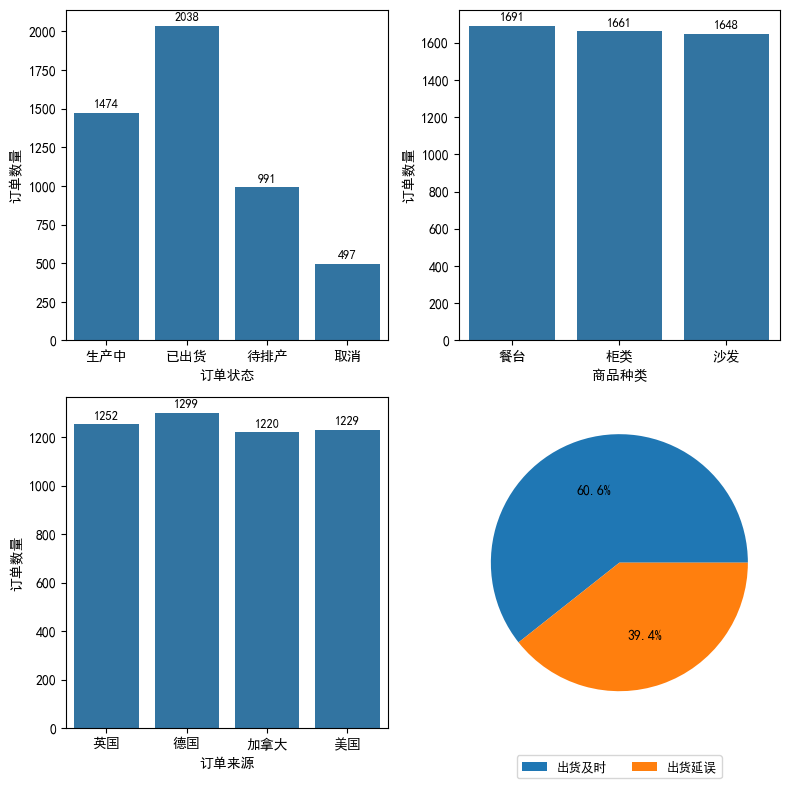

In [170]:
# 一、订单总览
# 1、不同订单状态 总览
plt.figure(figsize = (8, 8))
ax1 = plt.subplot2grid((2, 2), (0, 0))
sns.countplot(
    data = overview_df,
    x = 'order_status',
    ax = ax1
)

for container in ax1.containers:
    ax1.bar_label(container, 
                  label_type = 'edge',
                  fontsize = 9, 
                  padding = 2
                 )
ax1.set_xlabel('订单状态')
ax1.set_ylabel('订单数量')

# 2、不同种类订单 总览
ax2 = plt.subplot2grid((2, 2), (0, 1))
sns.countplot(
    data = overview_df,
    x = 'category',
    ax = ax2
)

for container in ax2.containers:
    ax2.bar_label(container, 
                  label_type = 'edge',
                  fontsize = 9, 
                  padding = 2
                 )
ax2.set_xlabel('商品种类')
ax2.set_ylabel('订单数量')

# 3、不同订单来源 总览
ax3 = plt.subplot2grid((2, 2), (1, 0))
sns.countplot(data = overview_df,
              x = 'country',
              ax = ax3
             )

for container in ax3.containers:
    ax3.bar_label(container, 
                  label_type = 'edge',
                  fontsize = 9, 
                  padding = 2
                 )
    
ax3.set_xlabel('订单来源')
ax3.set_ylabel('订单数量')

# 4、已出货订单准时与延误情况 总览
ax4 = plt.subplot2grid((2, 2), (1, 1))
pie_calculate = overview_df[overview_df['order_status'] == '已出货']['delay_status']

wedges, texts, autotexts = ax4.pie(
    pie_calculate.value_counts(),
    labels = None,
    autopct = "%1.1f%%",
)
ax4.legend(
    handles = wedges,
    labels = ['出货及时', '出货延误'],
    loc = 'upper center',
    bbox_to_anchor = (0.5, -0.08),
    ncol = 2,
    fontsize = 9
)
plt.tight_layout()
plt.show()

#总体上，订单状态比例分布大致为：4:3:2:1，取消率约为10%。
#不同商品种类的订单需求基本无差异
#不同国别订单总数基本无差异
#已出货订单的延误率很高，达到了39.4%，说明工厂生产组织存在问题。

In [188]:
# 二、生产分析
production_cycle = overview_df[['category', 'order_time', 'planed_ship_date']]
production_cycle['period'] = (production_cycle['planed_ship_date'] - production_cycle['order_time']).dt.days

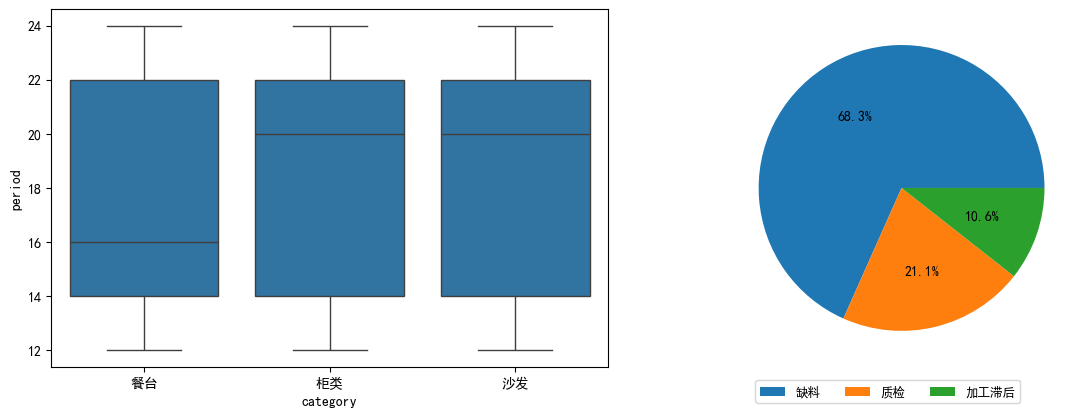

delay_reason
缺料      548
质检      169
加工滞后     85
Name: count, dtype: int64

In [204]:
# 21、不同家具的出货周期
plt.figure(figsize = (12, 8))
ax1 = plt.subplot2grid((2, 2), (0, 0))
sns.boxplot(data = production_cycle,
            x = 'category',
            y = 'period',
            width = 0.8,
            ax = ax1
           )
# 餐台订单出货周期典型值为16天，柜类和沙发出货周期典型值为20天，柜类和沙发的出货周期比餐台多4天。

#22、已出货商品的延误原因分布
ax2 = plt.subplot2grid((2, 2), (0, 1))
delay_pie = overview_df['delay_reason'].value_counts()
wedges, texts, autotexts = ax2.pie(
    overview_df['delay_reason'].value_counts(),
    labels = None,
    autopct = "%1.1f%%"
)
ax2.legend(
    handles = wedges,
    labels = ['缺料', '质检', '加工滞后'],
    bbox_to_anchor = (0.85, -0.02),
    ncol = 3,
    fontsize = 9
)


plt.tight_layout()
plt.show()

overview_df['delay_reason'].value_counts()
#可以看出，影响准时出货的主要因素是缺料，其次是质检，最后是加工进度滞后。
#但值得注意的是，质检不达标比例较高。缺料问题可以通过优化原料采购计划解决，但质量问题根源在生产过程把控，因此，有必要加强标准化施工。

In [187]:
production_cycle.head()

,category,order_time,planed_ship_date,period
0,餐台,2026-08-18,2026-09-09,22 days
1,柜类,2026-08-13,2026-09-04,22 days
2,餐台,2026-08-29,2026-09-10,12 days
3,餐台,2026-09-11,2026-09-25,14 days
4,沙发,2026-09-17,2026-10-07,20 days
